In [1]:
import numpy as np
import matplotlib.pyplot as plt

from funciones import xfantoma, matriz_proyeccion

In [2]:
D7 = [
    (1,0),
    (0,1),
    (1,1),
    (1,-1),
    (2,1),
    (1,2),
    (3,1)
]

A7, rayos7 = matriz_proyeccion(8, D7)

In [3]:
b7 = A7 @ xfantoma

In [4]:
np.random.seed(0)

z = np.random.randn(len(b7))

escala = np.sqrt(np.mean(b7**2))

sigma = 0.06

eta_sigma = sigma * escala * z
b_sigma = b7 + eta_sigma

#### a)

In [5]:
def E(x, A, b):
    residuo = A @ x - b
    return 0.5 * np.linalg.norm(residuo)**2


def grad_E(x, A, b):
    return A.T @ (A @ x - b)

In [6]:
#Construimos la Hessiana:
H = A7.T @ A7

#Y verificamos si es simétrica: 
print("¿H es simétrica?", np.allclose(H, H.T))

¿H es simétrica? True


La función objetivo

$$
E(x)=\frac{1}{2}\|A_7x-b_\sigma\|^2
$$

mide qué tan distintas son las mediciones generadas por una reconstrucción `x` respecto de las mediciones con ruido `b_sigma`.

El gradiente

$$
\nabla E(x)=A_7^T(A_7x-b_\sigma)
$$

indica la dirección en la que el costo aumenta más rápidamente.

La Hessiana es

$$
H=A_7^TA_7
$$

y en este problema es constante. Además, verificamos numéricamente que es simétrica.

#### b) Gradiente descendiente

Implementamos el método de gradiente descendiente usando la actualización:

$$
x_{t+1}=x_t-\alpha \nabla E(x_t)
$$

Esto significa que en cada iteración partimos del valor actual `x_t` y lo corregimos moviéndonos en la dirección contraria al gradiente.

El parámetro `alpha` controla el tamaño del paso que damos en cada iteración.

In [8]:
def gradiente_descendiente(A, b, alpha, max_iter=1000):
    
    x = np.zeros(A.shape[1])
    
    costos = []
    normas_gradiente = []
    
    for t in range(max_iter):
        
        grad = grad_E(x, A, b)
        
        costos.append(E(x, A, b))
        normas_gradiente.append(np.linalg.norm(grad))
        
        x = x - alpha * grad
    
    return x, costos, normas_gradiente

El gradiente descendiente comienza desde

$$
x_0=0
$$

y va modificando la reconstrucción en la dirección contraria al gradiente:

$$
x_{t+1}=x_t-\alpha\nabla E(x_t)
$$

En cada iteración registramos el costo y la norma del gradiente. Si el método converge, ambos deberían disminuir.

#### c) Elegir tasas de aprendizaje

Calculamos el mayor autovalor de \(H\):

In [9]:
autovalores = np.linalg.eigvalsh(H)

mu_max = np.max(autovalores)

print("mu_max =", mu_max)
print("2 / mu_max =", 2 / mu_max)

mu_max = 36.46340500801556
2 / mu_max = 0.054849512807713656


In [10]:
#Definimos tres tasas:
alpha_1 = 0.5 / mu_max
alpha_2 = 1.5 / mu_max
alpha_3 = 2.1 / mu_max

Las dos primeras están dentro de:

$$ 0<\alpha<\frac{2}{\mu_{\max}} $$

y la tercera está afuera.

In [11]:
x_gd1, costos1, grad1 = gradiente_descendiente(
    A7, b_sigma, alpha_1, max_iter=1000
)

x_gd2, costos2, grad2 = gradiente_descendiente(
    A7, b_sigma, alpha_2, max_iter=1000
)

x_gd3, costos3, grad3 = gradiente_descendiente(
    A7, b_sigma, alpha_3, max_iter=1000
)

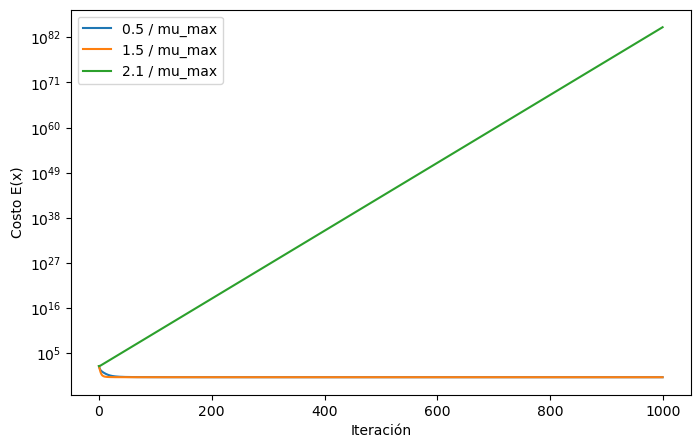

In [12]:
#Graficamos
plt.figure(figsize=(8,5))

plt.plot(costos1, label="0.5 / mu_max")
plt.plot(costos2, label="1.5 / mu_max")
plt.plot(costos3, label="2.1 / mu_max")

plt.yscale("log")
plt.xlabel("Iteración")
plt.ylabel("Costo E(x)")
plt.legend()
plt.show()

El mayor autovalor de la Hessiana determina el intervalo de estabilidad para la tasa de aprendizaje:

$$
0<\alpha<\frac{2}{\mu_{\max}}
$$

En el gráfico se observa que las tasas

$$
\alpha=\frac{0.5}{\mu_{\max}}
$$

y

$$
\alpha=\frac{1.5}{\mu_{\max}}
$$

se encuentran dentro del intervalo y hacen que el costo disminuya hasta estabilizarse.

En cambio,

$$
\alpha=\frac{2.1}{\mu_{\max}}
$$

queda fuera del intervalo permitido. En este caso el costo crece rápidamente y el método se vuelve inestable.

Esto muestra que una tasa de aprendizaje demasiado grande hace que las actualizaciones se pasen del mínimo y el algoritmo diverja.

### d) Método de Newton

Arrancamos desde:

In [13]:
x0 = np.zeros(64)

In [14]:
#Calculamos el gradiente inicial:

grad0 = grad_E(x0, A7, b_sigma)

Resolvemos:

$Hp=∇E(x_0)$

In [15]:
p = np.linalg.solve(H, grad0)

In [16]:
#Actualizamos:
x_newton = x0 - p

#Comparamos costos:
print("Costo inicial:", E(x0, A7, b_sigma))
print("Costo después de Newton:", E(x_newton, A7, b_sigma))

#Y lo comparamos contra mínimos cuadrados:
x_lstsq, _, _, _ = np.linalg.lstsq(A7, b_sigma, rcond=None)

print(
    "Diferencia Newton - lstsq:",
    np.linalg.norm(x_newton - x_lstsq)
)

Costo inicial: 72.87957387334156
Costo después de Newton: 0.1453512409793736
Diferencia Newton - lstsq: 7.51557224229898e-15


El método de Newton utiliza el gradiente y la Hessiana.

Primero resuelve:

$$
Hp_t=\nabla E(x_t)
$$

y luego actualiza:

$$
x_{t+1}=x_t-p_t
$$

En este problema alcanza la solución en una sola iteración porque la función objetivo es cuadrática y su Hessiana es constante. Por eso, Newton utiliza exactamente la curvatura del problema y puede llegar directamente al mínimo.

En nuestro caso, el costo inicial era aproximadamente:

$$
E(x_0)=72.88
$$

y después de una sola iteración de Newton bajó a:

$$
E(x_1)=0.145
$$

Además, la diferencia entre la solución obtenida con Newton y la obtenida con `np.linalg.lstsq` fue:

$$
7.52 \times 10^{-15}
$$

Este valor es prácticamente cero, por lo que ambas soluciones coinciden numéricamente.

#### e) Comparar gradiente, Newton y lstsq

In [17]:
#Para comparar, usamos una de las tasas estables. Por ejemplo:
x_gradiente = x_gd2

#Comparamos numéricamente:
print(
    "Gradiente vs lstsq:",
    np.linalg.norm(x_gradiente - x_lstsq)
)

print(
    "Newton vs lstsq:",
    np.linalg.norm(x_newton - x_lstsq)
)

Gradiente vs lstsq: 2.0933323139510425e-11
Newton vs lstsq: 7.51557224229898e-15


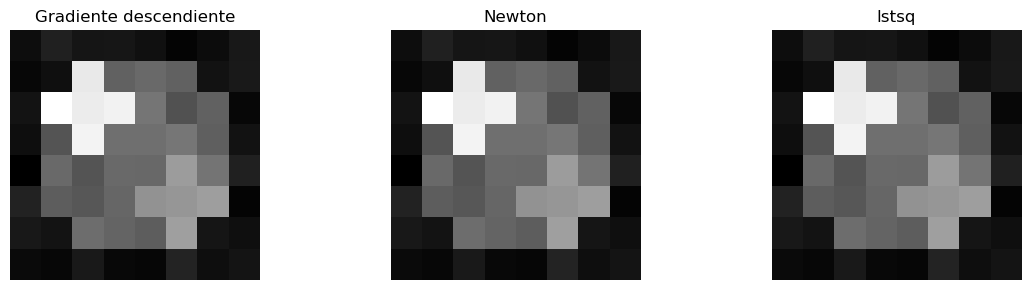

In [18]:
vmin = min(
    np.min(x_gradiente),
    np.min(x_newton),
    np.min(x_lstsq)
)

vmax = max(
    np.max(x_gradiente),
    np.max(x_newton),
    np.max(x_lstsq)
)

plt.figure(figsize=(12,3))

plt.subplot(1,3,1)
plt.imshow(x_gradiente.reshape(8,8), cmap="gray", vmin=vmin, vmax=vmax)
plt.title("Gradiente descendiente")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(x_newton.reshape(8,8), cmap="gray", vmin=vmin, vmax=vmax)
plt.title("Newton")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(x_lstsq.reshape(8,8), cmap="gray", vmin=vmin, vmax=vmax)
plt.title("lstsq")
plt.axis("off")

plt.tight_layout()
plt.show()

Las reconstrucciones obtenidas con gradiente descendiente, Newton y `np.linalg.lstsq` son prácticamente iguales.

`np.linalg.lstsq` obtiene directamente la solución de mínimos cuadrados, mientras que gradiente descendiente se acerca a esa solución de forma iterativa y depende de la tasa de aprendizaje y de la cantidad de iteraciones.

Newton, en cambio, utiliza la Hessiana del problema y alcanza prácticamente la misma solución que `lstsq` en una sola iteración.

La comparación visual confirma que los tres métodos están resolviendo el mismo problema de mínimos cuadrados.